2025-03-27 10:19:12.499512: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-03-27 10:19:12.603536: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-03-27 10:19:12.603552: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-03-27 10:19:12.629789: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-27 10:19:13.196002: W tensorflow/stream_executor/platform/de

Epoch 1/10


2025-03-27 10:19:13.832491: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-03-27 10:19:13.832677: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-03-27 10:19:13.832861: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-03-27 10:19:13.832920: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-03-27 10:19:13.832974: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not lo

73/73 [==============================] - 1s 4ms/step - loss: 0.0614 - val_loss: 0.0141
Epoch 2/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0102 - val_loss: 0.0057
Epoch 3/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0055 - val_loss: 0.0050
Epoch 4/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0053 - val_loss: 0.0049
Epoch 5/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0052 - val_loss: 0.0048
Epoch 6/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0052 - val_loss: 0.0048
Epoch 7/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0051 - val_loss: 0.0048
Epoch 8/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0051 - val_loss: 0.0048
Epoch 9/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0051 - val_loss: 0.0048
Epoch 10/10
645/645 [==============================] - 0s 614us/step


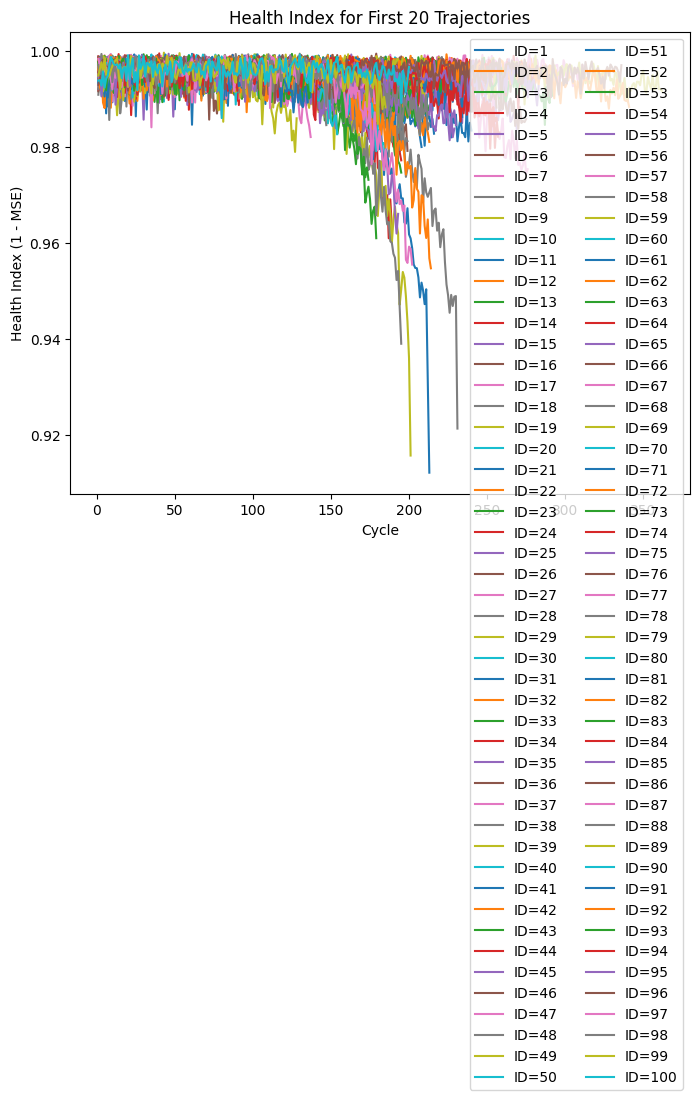

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model

# 1) LOAD AND PREPROCESS DATA
# ---------------------------------------------------------
column_names = [
    "id", "cycle", "setting1", "setting2", "setting3",
    "s1","s2","s3","s4","s5","s6","s7","s8","s9","s10",
    "s11","s12","s13","s14","s15","s16","s17","s18","s19","s20","s21"
]
df = pd.read_csv("~/Desktop/Dropbox/codeData/turbofanEngines/data/df_train.txt", 
                 delim_whitespace=True, 
                 header=None, 
                 names=column_names)

# Sensors to use (per your instruction)
sensors_used = ['s2', 's3', 's4', 's7', 's8', 's9', 
                's11','s12','s13','s14','s15','s17','s20','s21']
X = df[sensors_used].values

# Scale features to [0, 1]
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# 2) BUILD THE AUTOENCODER
# ---------------------------------------------------------
input_dim = X_scaled.shape[1]   # 14
latent_dim = 1                  # small latent space

# ENCODER
inputs = keras.Input(shape=(input_dim,))
x = layers.Dense(64, activation='relu')(inputs)
x = layers.Dense(16, activation='relu')(x)
latent = layers.Dense(latent_dim, activation='relu', name="latent")(x)

# DECODER
x = layers.Dense(16, activation='relu')(latent)
x = layers.Dense(64, activation='relu')(x)
outputs = layers.Dense(input_dim, activation='linear')(x)

autoencoder = Model(inputs, outputs)
autoencoder.compile(optimizer='adam', loss='mse')

# 3) TRAIN THE MODEL
# ---------------------------------------------------------
# Adjust epochs/batch_size as you like. 
history = autoencoder.fit(
    X_scaled, X_scaled,
    epochs=10,            # small number just for demo
    batch_size=256,
    validation_split=0.1,
    verbose=1
)

# 4) OBTAIN LATENT SPACE AND RECONSTRUCTION ERROR
# ---------------------------------------------------------
encoder = Model(autoencoder.input, autoencoder.get_layer("latent").output)

# Latent representation
latent_space = encoder.predict(X_scaled)

# Reconstruction
X_recon = autoencoder.predict(X_scaled)
mse = np.mean((X_scaled - X_recon)**2, axis=1)

# Health index (example: 1 - MSE, or exp(-MSE), etc.)
health_index = 1.0 - mse

# Create a DataFrame with ID, cycle, and HI
df_results = df[['id','cycle']].copy()
df_results['health_index'] = health_index

# 5) PLOT FIRST 20 TRAJECTORIES
# ---------------------------------------------------------
plt.figure(figsize=(8,6))
for engine_id in range(1, 101):
    df_eng = df_results[df_results['id'] == engine_id]
    plt.plot(df_eng['cycle'], df_eng['health_index'], label=f'ID={engine_id}')

plt.title("Health Index for First 20 Trajectories")
plt.xlabel("Cycle")
plt.ylabel("Health Index (1 - MSE)")
plt.legend(ncol=2)  # put legend in 2 columns so it’s not too tall
plt.show()


Epoch 1/10


2025-03-27 11:11:27.490379: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-03-27 11:11:27.490613: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-03-27 11:11:27.490820: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-03-27 11:11:27.490880: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-03-27 11:11:27.490934: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not lo

73/73 [==============================] - 1s 3ms/step - loss: 0.0563 - val_loss: 0.0168
Epoch 2/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0176 - val_loss: 0.0166
Epoch 3/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0173 - val_loss: 0.0162
Epoch 4/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0168 - val_loss: 0.0156
Epoch 5/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0157 - val_loss: 0.0140
Epoch 6/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0127 - val_loss: 0.0097
Epoch 7/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0083 - val_loss: 0.0064
Epoch 8/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0062 - val_loss: 0.0055
Epoch 9/10
73/73 [==============================] - 0s 2ms/step - loss: 0.0057 - val_loss: 0.0053
Epoch 10/10
645/645 [==============================] - 0s 636us/step


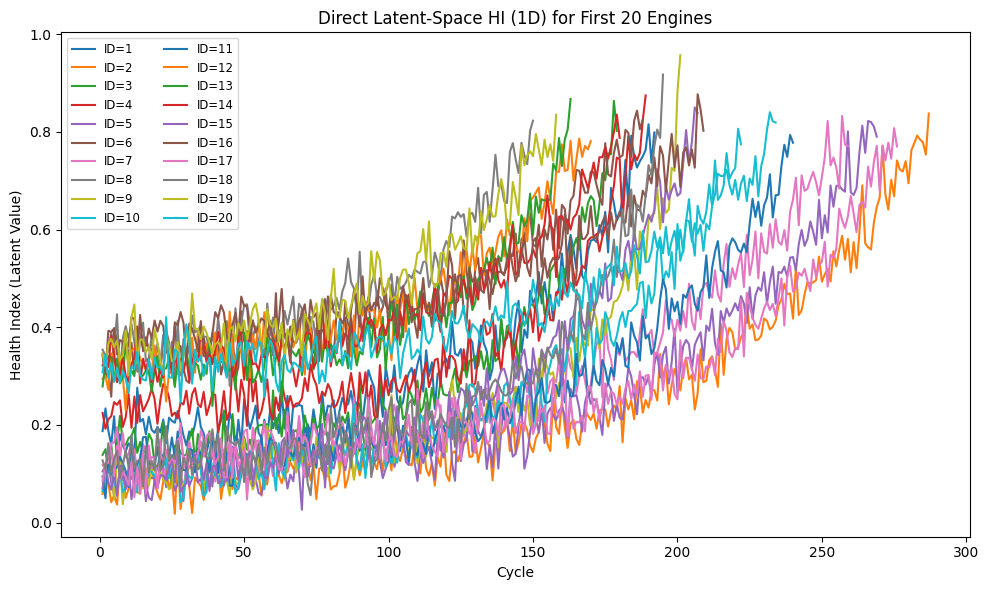

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# Load data
column_names = [
    "id", "cycle", "setting1", "setting2", "setting3",
    "s1","s2","s3","s4","s5","s6","s7","s8","s9","s10",
    "s11","s12","s13","s14","s15","s16","s17","s18","s19","s20","s21"
]
df = pd.read_csv('~/Desktop/Dropbox/codeData/turbofanEngines/data/df_train.txt', delim_whitespace=True, header=None, names=column_names)

# Use good sensors
sensors_used = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']
X = df[sensors_used].values

# Normalize features
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# Build Dense Autoencoder with latent_dim=1
input_dim = X_scaled.shape[1]
latent_dim = 1
inputs = Input(shape=(input_dim,))
x = Dense(64, activation='relu')(inputs)
x = Dense(16, activation='relu')(x)
latent = Dense(latent_dim, activation='linear', name="latent")(x)  # direct HI
x = Dense(16, activation='relu')(latent)
x = Dense(64, activation='relu')(x)
outputs = Dense(input_dim, activation='linear')(x)

autoencoder = Model(inputs, outputs)
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.fit(X_scaled, X_scaled, epochs=10, batch_size=256, validation_split=0.1, verbose=1)

# Get HI from latent space (directly)
encoder = Model(inputs, autoencoder.get_layer("latent").output)
hi_values = encoder.predict(X_scaled).flatten()

# Attach HI to dataframe
df['HI'] = hi_values

# Optional: Normalize HI to [0, 1] if you'd like consistency in plotting
df['HI'] = (df['HI'] - df['HI'].min()) / (df['HI'].max() - df['HI'].min())

# Plot HI for first 20 engines
plt.figure(figsize=(10, 6))
for eng_id in df['id'].unique()[:20]:
    df_eng = df[df['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng['HI'], label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value)")
plt.title("Direct Latent-Space HI (1D) for First 20 Engines")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()


Epoch 1/20
125/125 [==============================] - 1s 7ms/step - loss: 0.0421 - val_loss: 0.0171
Epoch 2/20
125/125 [==============================] - 1s 7ms/step - loss: 0.0161 - val_loss: 0.0140
Epoch 3/20
125/125 [==============================] - 1s 7ms/step - loss: 0.0146 - val_loss: 0.0134
Epoch 4/20
125/125 [==============================] - 1s 6ms/step - loss: 0.0140 - val_loss: 0.0126
Epoch 5/20
125/125 [==============================] - 1s 6ms/step - loss: 0.0103 - val_loss: 0.0063
Epoch 6/20
125/125 [==============================] - 1s 6ms/step - loss: 0.0063 - val_loss: 0.0060
Epoch 7/20
125/125 [==============================] - 1s 5ms/step - loss: 0.0061 - val_loss: 0.0059
Epoch 8/20
125/125 [==============================] - 1s 6ms/step - loss: 0.0060 - val_loss: 0.0058
Epoch 9/20
125/125 [==============================] - 1s 6ms/step - loss: 0.0059 - val_loss: 0.0057
Epoch 10/20
125/125 [==============================] - 1s 6ms/step - loss: 0.0059 - val_loss: 0.0057

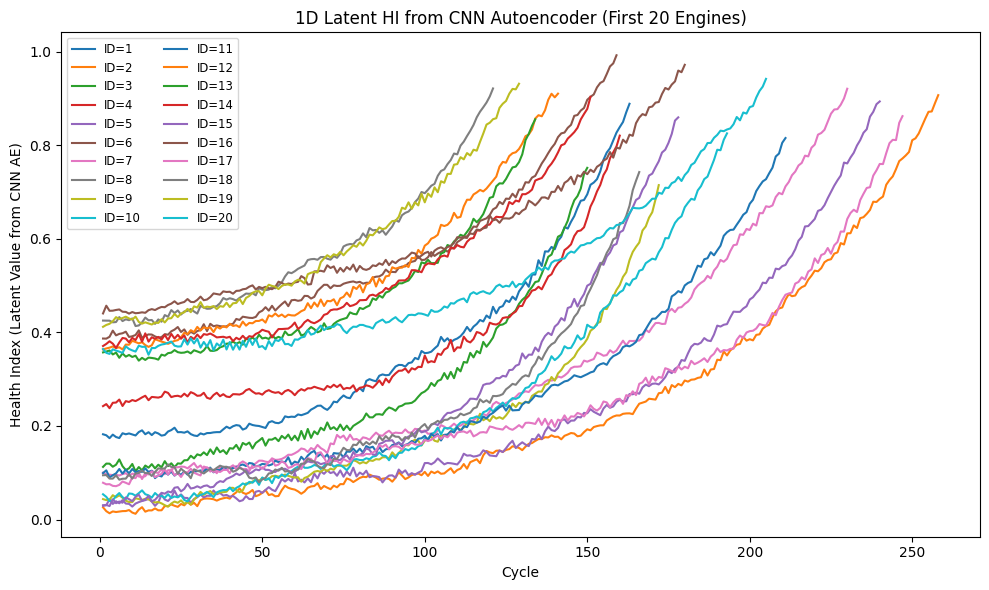

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, UpSampling1D, Dense, Flatten, Reshape, ZeroPadding1D
from tensorflow.keras.layers import GlobalAveragePooling1D, RepeatVector

# Load and prepare data
column_names = [
    "id", "cycle", "setting1", "setting2", "setting3",
    "s1","s2","s3","s4","s5","s6","s7","s8","s9","s10",
    "s11","s12","s13","s14","s15","s16","s17","s18","s19","s20","s21"
]
df = pd.read_csv('~/Desktop/Dropbox/codeData/turbofanEngines/data/df_train.txt', delim_whitespace=True, header=None, names=column_names)

# Good sensors
sensors_used = ['s2','s3','s4','s7','s8','s9','s11','s12','s13','s14','s15','s17','s20','s21']
window_size = 30  # Fixed sequence length
X_windows = []
engine_ids = []
start_cycles = []

# Build sliding windows from each engine
for eng_id in df['id'].unique():
    df_eng = df[df['id'] == eng_id].sort_values('cycle')
    data_eng = df_eng[sensors_used].values
    for start in range(0, len(data_eng) - window_size + 1):
        window = data_eng[start : start + window_size]
        X_windows.append(window)
        engine_ids.append(eng_id)
        start_cycles.append(start + 1)

X_windows = np.array(X_windows)  # (N, 30, 14)

# Normalize
N, seq_len, num_feats = X_windows.shape
X_flat = X_windows.reshape(N * seq_len, num_feats)
scaler = MinMaxScaler()
X_flat_scaled = scaler.fit_transform(X_flat)
X_scaled = X_flat_scaled.reshape(N, seq_len, num_feats)

# Build 1D CNN Autoencoder with latent_dim = 1
inputs = Input(shape=(seq_len, num_feats))
x = Conv1D(32, 3, activation='relu', padding='same')(inputs)
x = MaxPooling1D(2, padding='same')(x)
x = Conv1D(16, 3, activation='relu', padding='same')(x)
x = MaxPooling1D(2, padding='same')(x)
x = GlobalAveragePooling1D()(x)
latent = Dense(1, name='latent')(x)  # HI directly here

x = Dense((seq_len // 4) * 16, activation='relu')(latent)  # (7 * 16)
x = Reshape((seq_len // 4, 16))(x)  # Shape: (7, 16)
x = UpSampling1D(2)(x)  # Shape: (14, 16)
x = Conv1D(32, 3, activation='relu', padding='same')(x)  # Shape: (14, 32)
x = UpSampling1D(2)(x)  # Shape: (28, 32)
x = ZeroPadding1D(padding=(1, 1))(x)  # Pad to get (30, 32)
decoded = Conv1D(num_feats, 3, activation='linear', padding='same')(x)  # Shape: (30, 14)


cnn_ae = Model(inputs, decoded)
cnn_ae.compile(optimizer='adam', loss='mse')
cnn_ae.fit(X_scaled, X_scaled, epochs=20, batch_size=128, validation_split=0.1, verbose=1)

# Extract latent HI values
encoder = Model(inputs, cnn_ae.get_layer('latent').output)
hi_values = encoder.predict(X_scaled).flatten()

# Normalize HI (optional)
hi_values = (hi_values - hi_values.min()) / (hi_values.max() - hi_values.min())

# Build dataframe for plotting
df_hi = pd.DataFrame({
    'id': engine_ids,
    'cycle': start_cycles,
    'HI': hi_values
})

# Plot first 20 engines
plt.figure(figsize=(10, 6))
for eng_id in df_hi['id'].unique()[:20]:
    df_eng = df_hi[df_hi['id'] == eng_id]
    plt.plot(df_eng['cycle'], df_eng['HI'], label=f'ID={eng_id}')
plt.xlabel("Cycle")
plt.ylabel("Health Index (Latent Value from CNN AE)")
plt.title("1D Latent HI from CNN Autoencoder (First 20 Engines)")
plt.legend(ncol=2, fontsize='small')
plt.tight_layout()
plt.show()
